> **Verzija s rješenjima — samo za nastavnika.**

# V2: Korpusi i BPE

**I051 Računalno jezikoslovlje** - vježbe uz _2. predavanje_.

| | Predavanje | Vježbe |
|---|---|---|
| 1 | Koliko riječi ima jezik? | korpusi u NLTK, pojavnice i različnice |
| 2 | Heapsov zakon | kako raste rječnik: engleski i hrvatski |
| 3 | BPE | BPE s bibliotekom tokenizers: kako nastaju tokeni |

# 0. Priprema u VSCode-u

Prije vježbi potrebno je imati:

1. instaliran **Python** (python.org; pri instalaciji na Windowsima označite *Add python.exe to PATH*),
2. u VSCode-u instalirana proširenja **Python** i **Jupyter**,
3. odabran Jupyter kernel: u bilježnici gore desno **Select Kernel → Python Environments…** → vaša instalacija Pythona. Ako VSCode ponudi instalaciju paketa `ipykernel`, prihvatite.

Zatim u sljedećoj ćeliji instaliramo pakete koje koristimo (`nltk` i `matplotlib`, popisani u datoteci `requirements.txt`). Znak `%` na početku označava naredbu za Jupyter: `pip` se pokreće u istom Pythonu u kojem radi bilježnica. Ćeliju je dovoljno pokrenuti jednom.

In [ ]:
%pip install -r requirements.txt

Pri prvom pokretanju paketa potrebno je preuzeti korpuse s interneta. 

In [1]:
# preuzimanje potrebnih korpusa
import nltk
nltk.download("brown")
nltk.download("gutenberg")
# ovo nekad treba, tokenizacija rečenica
nltk.download("punkt_tab")

[nltk_data] Downloading package brown to
[nltk_data]     C:\Users\dseve\AppData\Roaming\nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\dseve\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\dseve\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

# 1. Upoznajmo korpuse

**Korpus** je zbirka tekstova odabranih s nekom svrhom. NLTK dolazi s desecima korpusa, a mi koristimo dva engleska:

* **Brown** (1961.) — prvi veliki računalni korpus američkog engleskog: oko milijun riječi iz 500 tekstova razvrstanih u 15 žanrova (kategorija),
* **Gutenberg** — 18 knjiga iz projekta Gutenberg (Biblija, Shakespeare, Jane Austen …).

Svi korpusi u NLTK-u imaju iste metode:

| metoda | što vraća |
|---|---|
| `fileids()` | popis datoteka |
| `categories()` | popis kategorija (samo Brown) |
| `words()` | sve riječi korpusa (zapravo tokene: i interpunkciju) |
| `sents()` | sve rečenice; svaka rečenica je lista riječi |

## 1.1 Brown i Gutenberg

In [2]:
# koristimo korpuse
from nltk.corpus import brown, gutenberg

print(brown.categories()[:5])               # prvih 5 kategorija
print(brown.fileids()[:5])                  # prvih 5 datoteka
print(brown.words(categories="news")[:10])  # prvih 10 riječi iz kategorije "news"

['adventure', 'belles_lettres', 'editorial', 'fiction', 'government']
['ca01', 'ca02', 'ca03', 'ca04', 'ca05']
['The', 'Fulton', 'County', 'Grand', 'Jury', 'said', 'Friday', 'an', 'investigation', 'of']


In [3]:
brown.sents(categories="news")[:2]  # prve 2 rečenice iz kategorije "news"

[['The',
  'Fulton',
  'County',
  'Grand',
  'Jury',
  'said',
  'Friday',
  'an',
  'investigation',
  'of',
  "Atlanta's",
  'recent',
  'primary',
  'election',
  'produced',
  '``',
  'no',
  'evidence',
  "''",
  'that',
  'any',
  'irregularities',
  'took',
  'place',
  '.'],
 ['The',
  'jury',
  'further',
  'said',
  'in',
  'term-end',
  'presentments',
  'that',
  'the',
  'City',
  'Executive',
  'Committee',
  ',',
  'which',
  'had',
  'over-all',
  'charge',
  'of',
  'the',
  'election',
  ',',
  '``',
  'deserves',
  'the',
  'praise',
  'and',
  'thanks',
  'of',
  'the',
  'City',
  'of',
  'Atlanta',
  "''",
  'for',
  'the',
  'manner',
  'in',
  'which',
  'the',
  'election',
  'was',
  'conducted',
  '.']]

In [4]:
# gutenberg korpus
print(gutenberg.fileids()[:5])                # prvih 5 datoteka
print(gutenberg.words("bible-kjv.txt")[:30])  # prvih 30 riječi Biblije
gutenberg.sents("bible-kjv.txt")[:5]          # prvih 5 rečenica Biblije

['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt']
['[', 'The', 'King', 'James', 'Bible', ']', 'The', 'Old', 'Testament', 'of', 'the', 'King', 'James', 'Bible', 'The', 'First', 'Book', 'of', 'Moses', ':', 'Called', 'Genesis', '1', ':', '1', 'In', 'the', 'beginning', 'God', 'created']


[['[', 'The', 'King', 'James', 'Bible', ']'],
 ['The', 'Old', 'Testament', 'of', 'the', 'King', 'James', 'Bible'],
 ['The', 'First', 'Book', 'of', 'Moses', ':', 'Called', 'Genesis'],
 ['1',
  ':',
  '1',
  'In',
  'the',
  'beginning',
  'God',
  'created',
  'the',
  'heaven',
  'and',
  'the',
  'earth',
  '.'],
 ['1',
  ':',
  '2',
  'And',
  'the',
  'earth',
  'was',
  'without',
  'form',
  ',',
  'and',
  'void',
  ';',
  'and',
  'darkness',
  'was',
  'upon',
  'the',
  'face',
  'of',
  'the',
  'deep',
  '.']]

**Pokušajte:** ispišite prvih 20 riječi iz kategorije `romance` i prve tri rečenice Hamleta (`shakespeare-hamlet.txt`).

In [5]:
print(brown.words(categories="romance")[:20])
gutenberg.sents("shakespeare-hamlet.txt")[:3]

['They', 'neither', 'liked', 'nor', 'disliked', 'the', 'Old', 'Man', '.', 'To', 'them', 'he', 'could', 'have', 'been', 'the', 'broken', 'bell', 'in', 'the']


[['[',
  'The',
  'Tragedie',
  'of',
  'Hamlet',
  'by',
  'William',
  'Shakespeare',
  '1599',
  ']'],
 ['Actus', 'Primus', '.'],
 ['Scoena', 'Prima', '.']]

## 1.2 Hrvatski korpus

NLTK **nema** hrvatski korpus, ali ga možemo definirati sami. Korpus u NLTK-u nije ništa posebno: to su **datoteke** na disku i **čitač** (engl. *corpus reader*) koji zna kako ih rastaviti na riječi i rečenice. Brown i Gutenberg su upravo to.

Za hrvatski koristimo korpus **SET** iz projekta Universal Dependencies (UD Croatian SET): hrvatske vijesti s portala SETimes, iste kao u V1. U mapi `data` su dvije datoteke, `hr_train.txt` i `hr_test.txt`. U njima je **jedna rečenica po retku**, a riječi i interpunkcija odvojeni su razmakom. Čitaču to kažemo s dva tokenizatora:

* `WhitespaceTokenizer` — riječi su odvojene razmakom,
* `LineTokenizer` — svaka rečenica je u svom retku.

In [6]:
# NLTK nema hrvatski korpus, pa ga definiramo sami iz datoteka u mapi data
import os
from nltk.corpus.reader import PlaintextCorpusReader
from nltk.tokenize import WhitespaceTokenizer, LineTokenizer

nltk.data.path.append(os.path.abspath("data"))  # NLTK smije čitati samo dopuštene mape: dopustimo mapu data

hr = PlaintextCorpusReader(
    "data", ["hr_train.txt", "hr_test.txt"],    # mapa i datoteke korpusa
    word_tokenizer=WhitespaceTokenizer(),       # riječi su odvojene razmakom
    sent_tokenizer=LineTokenizer(),             # jedna rečenica po retku
)

Sada hrvatski korpus ima iste metode kao Brown:

In [7]:
print(hr.fileids())                       # datoteke korpusa
print(len(hr.sents("hr_train.txt")))      # broj rečenica u hr_train.txt
print(len(hr.words("hr_train.txt")))      # broj riječi (tokena) u hr_train.txt
hr.sents("hr_train.txt")[:2]              # prve 2 rečenice

['hr_train.txt', 'hr_test.txt']
6914
152857


[['Kazna', 'medijskom', 'mogulu', 'obnovila', 'raspravu', 'u', 'Makedoniji'],
 ['Neki',
  'tvrde',
  'da',
  'je',
  'presuda',
  'Veliji',
  'Ramkovskom',
  'napad',
  'na',
  'slobodu',
  'medija',
  ',',
  'dok',
  'drugi',
  'tvrde',
  'kako',
  'dokazi',
  'o',
  'njegovim',
  'kaznenim',
  'djelima',
  'govore',
  'suprotno',
  '.']]

## 1.3 Konkordancija

**Konkordancija** prikazuje svako pojavljivanje riječi s nekoliko riječi lijevo i desno, poravnato tako da je tražena riječ uvijek u sredini — tako lingvisti proučavaju kako se riječ koristi.

NLTK za to ima `nltk.Text`: listu riječi omotamo u `Text` i dobijemo metode za istraživanje teksta, među njima `concordance`.

In [8]:
hr_words = list(hr.words("hr_train.txt"))  # riječi hrvatskog korpusa kao obična lista
brown_words = list(brown.words())

hr_text = nltk.Text(hr_words)
hr_text.concordance("jezik")

Displaying 11 of 11 matches:
godina starosti koji govore engleski jezik i to je možda razlog što samo 5 do 1
. " Ako čitamo izvješće vidimo da je jezik pozitivniji nego prošle godine te se
ske ili Italije jer tamo lakše nauče jezik " , kaže Barascu i dodaje : " Zbog o
e zna da čakavski nije dijalekt nego jezik , nije bitno za Hrvatsku ali loše zv
a internetskog sustava . Na engleski jezik otpada osamdeset posto polaznika jez
h tečajeva , a slijedi ga španjolski jezik . U salonu za masažu u Gundulićevoj 
je draže što je ona našla zajednički jezik za ljude različitih shvaćanja . Osim
a poticati da slobodno izabere jedan jezik , različit od njegova materinskog je
iz filistejskog ropstva . Ukrajinski jezik je po broju govornika drugi slavensk
e po broju govornika drugi slavenski jezik i pripada skupini istočnoslavenskih 
ata , ostalo na odjelima za njemački jezik , arheologije i knjižničarstva . Jed


In [9]:
nltk.Text(brown_words).concordance("language", lines=5)  # samo prvih 5 redaka

Displaying 5 of 109 matches:
C. Miller . And you think you have language problems . The week went along bri
ocial science , pure science , and language ; ; history , biography , and educ
country where the diet , culture , language and living conditions will be diff
e lost . This , in more diplomatic language , is what Adlai Stevenson told the
en invited . This is going to be a language lesson , and you can master it in 


**Pokušajte:** potražite neku riječ po svom izboru u oba korpusa. Po čemu se vidi da je hrvatski korpus zbirka vijesti?

In [10]:
hr_text.concordance("Hrvatska", lines=5)

Displaying 5 of 98 matches:
hvaćenim parlamentarnim sustavom . Hrvatska pozvana na ubrzanje reformi koje t
 na ubrzanje reformi koje traži EU Hrvatska u sljedeća tri mjeseca mora ubrzat
 na ubrzanje reformskih napora . " Hrvatska ima dobre izglede na napredak , al
tak pregovora u 2009 , uz uvjet da Hrvatska ispuni niz zadanih uvjeta . Jandro
13. godine . 25. lipnja ove godine Hrvatska je imala dvostruki razlog za slavl


# 2. Koliko riječi ima korpus?

S predavanja: **pojavnica** je svako pojavljivanje riječi u tekstu, a **različnica** svaka različita riječ. Broj pojavnica označavamo s $N$, a broj različnica s $|V|$ (rječnik $V$ je skup različnica).

## 2.1 Pojavnice i različnice

Provjerimo na rečenici s predavanja (bez interpunkcije, malim slovima). Skup (`set`) sadrži svaku riječ samo jednom:

In [11]:
sentence = "na stolu je knjiga na knjizi je olovka a na olovki je mrav"
words = sentence.split()

print(len(words))       # N: broj pojavnica
print(set(words))       # skup: svaka riječ samo jednom
print(len(set(words)))  # |V|: broj različnica

13
{'olovki', 'knjiga', 'na', 'knjizi', 'olovka', 'je', 'a', 'mrav', 'stolu'}
9


Isto na korpusu Brown:

In [12]:
len(brown_words), len(set(brown_words))  # (N, |V|)

(1161192, 56057)

Brojimo i interpunkciju, a *The* i *the* računamo kao dvije različnice. Zato ćemo riječi **očistiti**: zadržati samo riječi od slova (`isalpha`) i pretvoriti ih u mala slova (`lower`).

In [13]:
print("The".lower(), "the".isalpha(), ",".isalpha(), "1961".isalpha())

brown_clean = [w.lower() for w in brown_words if w.isalpha()]  # samo riječi od slova, malim slovima
len(brown_clean), len(set(brown_clean))  # (N, |V|)

the True False False


(981716, 40234)

Usporedite s tablicom »Koliko riječi ima jezik?« s predavanja (Brown: 1 mil. pojavnica, 38 tis. različnica).

### Zadatak 1

Isto čišćenje trebat će nam za svaki korpus. Napišite funkciju `clean(words)` koja vraća listu riječi od slova, malim slovima (komprehenzija iz ćelije iznad). Zatim izračunajte $N$ i $|V|$ za hrvatski korpus i za Hamleta i ispišite ih kao tablicu.

In [14]:
def clean(words):
    return [w.lower() for w in words if w.isalpha()]

hr_clean = clean(hr_words)
hamlet_clean = clean(gutenberg.words("shakespeare-hamlet.txt"))

corpora = {"Brown": brown_clean, "Hamlet": hamlet_clean, "hrvatski (SET)": hr_clean}
print(f"{'korpus':15} {'N':>9} {'|V|':>7}")
for name, words in corpora.items():
    print(f"{name:15} {len(words):>9} {len(set(words)):>7}")

korpus                  N     |V|
Brown              981716   40234
Hamlet              30266    4699
hrvatski (SET)     131077   28919


**Za razmisliti:** hrvatski korpus ima oko 7 puta manje pojavnica od Browna. Usporedite broj različnica. Kako to objašnjavate? (Pomoć: koliko oblika ima riječ *knjiga*?)

## 2.2 Najčešće riječi

`nltk.FreqDist` za svaku riječ broji koliko se puta pojavila (frekvencijska razdioba).

In [15]:
brown_fd = nltk.FreqDist(brown_clean)
print(brown_fd["language"])     # koliko se puta pojavila jedna riječ
brown_fd.most_common(10)        # 10 najčešćih riječi

109


[('the', 69971),
 ('of', 36412),
 ('and', 28853),
 ('to', 26158),
 ('a', 23195),
 ('in', 21337),
 ('that', 10594),
 ('is', 10109),
 ('was', 9815),
 ('he', 9548)]

[('je', 4674), ('u', 4542), ('i', 4517), ('se', 2145), ('na', 2125), ('za', 1801), ('su', 1469), ('da', 1432), ('od', 982), ('s', 901)]


<Axes: xlabel='Samples', ylabel='Counts'>

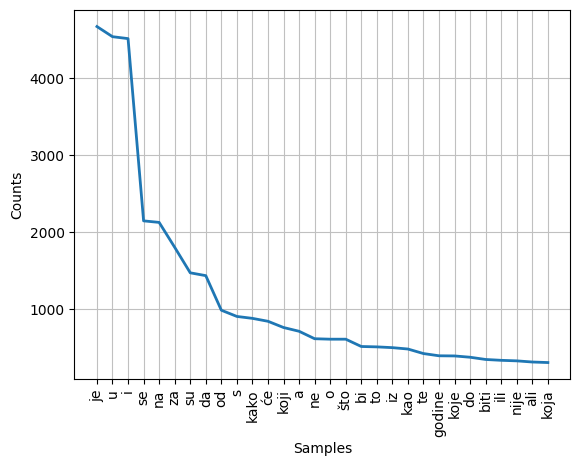

In [17]:
hr_fd = nltk.FreqDist(hr_clean)
print(hr_fd.most_common(10))
hr_fd.plot(30)                  # graf 30 najčešćih riječi

U oba jezika najčešće su kratke **funkcijske** riječi: veznici, prijedlozi, pomoćni glagoli.

**Pokušajte:** koliko se puta u hrvatskom korpusu pojavljuju *predsjednik*, *predsjednika*, *predsjedniku* i *predsjednikom*? Što to znači za broj različnica?

In [ ]:
{w: hr_fd[w] for w in ["predsjednik", "predsjednika", "predsjedniku", "predsjednikom"]}

## 2.3 Žanr

Isti jezik, ali različiti tekstovi imaju različite riječi (predavanje: »Tekst ne nastaje niotkuda«). `nltk.ConditionalFreqDist` broji riječi posebno za svaki **uvjet** — ovdje žanr. Klasičan primjer iz knjige o NLTK-u su modalni glagoli:

In [ ]:
print(brown.categories())  # svih 15 žanrova

genres = ["news", "religion", "hobbies", "science_fiction", "romance", "humor"]
modals = ["can", "could", "may", "might", "must", "will"]

# parovi (žanr, riječ) za sve riječi odabranih žanrova
cfd = nltk.ConditionalFreqDist(
    (genre, word.lower())
    for genre in genres
    for word in brown.words(categories=genre)
)
cfd.tabulate(conditions=genres, samples=modals)

**Za razmisliti:** u kojem je žanru najčešći *will*, a u kojem *could*? Zašto? Bi li model naučen samo na vijestima dobro razumio roman?

# 3. Heapsov zakon: kako raste rječnik

S predavanja: što je korpus veći, to ima više različnica — rječnik ne prestaje rasti. Heapsov zakon kaže $|V| = kN^\beta$, gdje su $k$ i $\beta$ pozitivne konstante, $0 < \beta < 1$.

Pratimo rast rječnika: čitamo riječ po riječ i nakon svake riječi zapišemo koliko smo različitih riječi dosad vidjeli.

In [18]:
seen = set()  # različnice koje smo dosad vidjeli
for n, w in enumerate(hr_clean[:15], start=1):  # n = redni broj riječi: 1, 2, 3, ...
    seen.add(w)
    print(n, len(seen), w)  # N, |V|, riječ

1 1 kazna
2 2 medijskom
3 3 mogulu
4 4 obnovila
5 5 raspravu
6 6 u
7 7 makedoniji
8 8 neki
9 9 tvrde
10 10 da
11 11 je
12 12 presuda
13 13 veliji
14 14 ramkovskom
15 15 napad


Kad se riječ ponovi, $N$ raste, a $|V|$ ostaje isti. Za cijeli korpus ne trebamo svaki korak — dovoljno je zapisati stanje nakon svakih, recimo, 5000 riječi.

### Zadatak 2

Napišite funkciju `vocab_growth(words, step)` koja vraća listu parova `(N, |V|)` nakon svakih `step` riječi. Pomoć: prilagodite petlju iznad; `n % step == 0` je istina kad je `n` višekratnik od `step`.

In [19]:
def vocab_growth(words, step=5000):
    seen = set()
    points = []
    for n, w in enumerate(words, start=1):
        seen.add(w)
        if n % step == 0:
            points.append((n, len(seen)))
    return points

vocab_growth(hr_clean)[:3]

[(5000, 2213), (10000, 4077), (15000, 5595)]

Usporedimo engleski i hrvatski na **jednakom** broju pojavnica. Brown počinje vijestima, pa uspoređujemo vijesti s vijestima.

(130000, 28713) (130000, 14205)


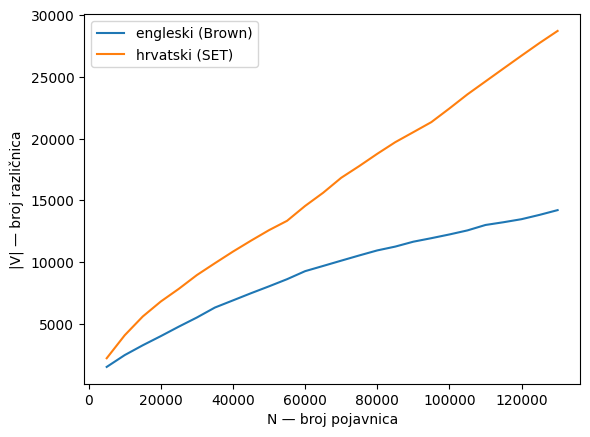

In [20]:
import matplotlib.pyplot as plt

en_clean = brown_clean[:len(hr_clean)]  # engleski tekst iste duljine kao hrvatski korpus
hr_points = vocab_growth(hr_clean)
en_points = vocab_growth(en_clean)
print(hr_points[-1], en_points[-1])     # (N, |V|) za cijeli tekst

for points, label in [(en_points, "engleski (Brown)"), (hr_points, "hrvatski (SET)")]:
    ns, vs = zip(*points)  # lista parova (N, |V|) -> dvije liste: N i |V|
    plt.plot(ns, vs, label=label)
plt.xlabel("N — broj pojavnica")
plt.ylabel("|V| — broj različnica")
plt.legend()
plt.show()

Procijenimo $\beta$. Ako za $N_1$ pojavnica imamo $|V_1|$ različnica, a za $N_2 = 2N_1$ imamo $|V_2|$, iz Heapsova zakona slijedi

$$\beta = \frac{\log(|V_2| / |V_1|)}{\log(N_2 / N_1)}.$$

In [21]:
import math

def beta(points):
    n1, v1 = points[len(points) // 2 - 1]  # polovica teksta
    n2, v2 = points[-1]                    # cijeli tekst
    return math.log(v2 / v1) / math.log(n2 / n1)

beta(en_points), beta(hr_points)

(0.5524259234752792, 0.879233537186454)

**Za razmisliti:** za engleske korpuse $\beta$ je obično između 0,44 i 0,56. Zašto je za hrvatski veći? Što to znači za model kojemu je rječnik popis riječi?

# 4. BPE s bibliotekom tokenizers

S predavanja: BPE kreće od pojedinačnih znakova i ponavlja jedan korak — **spoji najčešći par susjednih simbola** — dok rječnik ne naraste do zadane veličine. Algoritam ne pišemo sami: koristimo biblioteku **tokenizers** (Hugging Face), na kojoj rade tokenizatori velikih jezičnih modela. Naš je zadatak razumjeti što radi.

Tokenizator se priprema u nekoliko redaka; zapakirat ćemo ih u funkciju `train_bpe` da je poslije pozivamo jednim retkom:

* `vocab_size` je veličina rječnika: početni znakovi + naučena spajanja,
* `Metaspace` pretvara razmak u `▁`, kao na predavanju,
* znak koji tokenizator nije vidio pri učenju postaje `[UNK]` (nepoznat); i `[UNK]` je jedan token rječnika.

In [ ]:
%pip install tokenizers

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

def train_bpe(sentences, vocab_size):
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))   # BPE; nepoznati znak -> [UNK]
    tokenizer.pre_tokenizer = pre_tokenizers.Metaspace()   # razmak -> ▁
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=False)
    tokenizer.train_from_iterator(sentences, trainer)      # učenje na listi rečenica
    return tokenizer

## 4.1 Mali korpus s predavanja

Korpus je *set new new renew reset renew*. U njemu je 7 različitih znakova (▁ e n r s t w), pa uz `[UNK]` početni rječnik ima 8 tokena. Povećamo li rječnik za jedan, tokenizator smije naučiti **jedno spajanje više**. Tako BPE vidimo korak po korak:

In [ ]:
toy = ["set new new renew reset renew"]
words = ["set", "new", "renew", "reset"]

for k in range(9):                  # k = broj spajanja
    bpe = train_bpe(toy, 8 + k)     # 8 početnih tokena + k spajanja
    print(k, [" ".join(bpe.encode(w).tokens) for w in words])

Usporedite sa slajdom »BPE unutar riječi«. Već prvi korak je drukčiji: parovi *n e* i *e w* pojavljuju se jednako često (po 4 puta), a knjiga i biblioteka kod **izjednačenja** biraju različito. Algoritam je isti i na kraju opet nastaju *new*, *▁re*, *set* i *▁renew*.

Rječnik nakon 8 spajanja: početni tokeni su ostali, samo su dodani novi.

In [ ]:
print(bpe.get_vocab_size())
sorted(bpe.get_vocab())   # svi tokeni rječnika, abecedno

**Pokušajte:** dodajte u korpus tri puta riječ *newer* i ponovite petlju (u popis `words` dodajte i *newer*). Mijenja li se što BPE spaja?

In [ ]:
toy2 = ["set new new renew reset renew newer newer newer"]
for k in range(9):
    bpe = train_bpe(toy2, 8 + k)
    print(k, [" ".join(bpe.encode(w).tokens) for w in words + ["newer"]])

## 4.2 BPE na hrvatskim vijestima

Tokenizator uči iz rečenica zapisanih kao tekst, pa očišćene riječi svake rečenice spojimo razmakom.

In [ ]:
hr_sentences = [" ".join(clean(sent)) for sent in hr.sents("hr_train.txt")]
hr_bpe = train_bpe(hr_sentences, 1000)   # rječnik od 1000 tokena; traje oko sekunde
hr_bpe.encode("računalno jezikoslovlje proučava hrvatski jezik").tokens

Tokenizator pamti naučena spajanja redom kojim ih je naučio. Ispišimo prvih 15:

In [ ]:
import json

merges_hr = json.loads(hr_bpe.to_str())["model"]["merges"]   # opis tokenizatora u formatu JSON
print(len(merges_hr), "spajanja")
print(merges_hr[:15])   # usporedite sa slajdom »BPE na hrvatskim vijestima«

## 4.3 Koder: rastavljanje nove riječi

Koder primjenjuje naučena spajanja na novu riječ **istim redom** kojim su naučena. Riječ koje nema u korpusu za učenje rastavi se na poznate dijelove:

In [ ]:
for word in ["jezikoslovlje", "jezikoslovčev", "neovisnost", "mačkama"]:
    print(f"{word:15} {hr_bpe.encode(word).tokens}")

**Za razmisliti:** jesu li dobiveni dijelovi morfemi?

### Zadatak 3

Što je rječnik veći, to su tokeni dulji. Naučite tokenizator s rječnikom od 100, 300, 1000 i 5000 tokena i za svaku veličinu ispišite tokene riječi *jezikoslovlje* i *predsjednik*. Pri kojoj veličini *predsjednik* postaje jedan token?

In [ ]:
for size in [100, 300, 1000, 5000]:
    bpe = train_bpe(hr_sentences, size)
    print(size, bpe.encode("jezikoslovlje").tokens, bpe.encode("predsjednik").tokens)

## 4.4 Engleski tokenizator na hrvatskom tekstu

Na predavanju: tokenizatori naučeni pretežno na engleskom **usitnjavaju** hrvatski. Naučimo isti tokenizator na engleskim vijestima iz korpusa Brown i tokenizirajmo hrvatsku rečenicu.

In [ ]:
en_sentences = [" ".join(clean(sent)) for sent in brown.sents(categories="news")]
en_bpe = train_bpe(en_sentences, 1000)

sentence = "računalno jezikoslovlje proučava hrvatski jezik"
print(len(hr_bpe.encode(sentence).tokens), hr_bpe.encode(sentence).tokens)
print(len(en_bpe.encode(sentence).tokens), en_bpe.encode(sentence).tokens)

Engleski tokenizator nikad nije vidio slovo *č*, pa ga zamjenjuje s `[UNK]`. Pravi modeli zato BPE rade nad **bajtovima** (slajd »BPE u praksi«): svaki znak je niz bajtova, pa nepoznatih tokena nema.

**Fertilnost** (iz V1) je prosječan broj tokena po riječi. Izmjerimo je na hrvatskim rečenicama koje nisu bile u korpusu za učenje — to je druga datoteka našeg korpusa, `hr_test.txt`.

In [ ]:
def fertility(tokenizer, sentences):
    n_tokens = sum(len(tokenizer.encode(s).tokens) for s in sentences)
    n_words = sum(len(s.split()) for s in sentences)
    return n_tokens / n_words

hr_test_sentences = [" ".join(clean(sent)) for sent in hr.sents("hr_test.txt")]
fertility(hr_bpe, hr_test_sentences), fertility(en_bpe, hr_test_sentences)

**Za razmisliti:** koliko tokena po riječi troši engleski tokenizator na hrvatskom tekstu? Što to znači za duljinu konteksta i cijenu korištenja velikog jezičnog modela na hrvatskom?